# Wie verändert ein Asthma-Medikament die Zellen der Atemwege?

Bei **Asthma** sind die Atemwege entzündet: Sie schwellen an, bilden Schleim und die Muskeln um sie herum ziehen sich zusammen, sodass das Atmen schwerfällt. Viele Asthma-Kranke nehmen **Glucocorticoide**, Medikamente, die mit dem Stresshormon Cortisol verwandt sind. Eines davon ist **Dexamethason**. Es beruhigt die Entzündung, aber wie?

Forschende (Himes et al. 2014) haben **glatte Muskelzellen der Atemwege** von **4 Spendern** (Menschen) genommen. Zellen jedes Spenders wurden 18 Stunden mit Dexamethason behandelt, andere Zellen desselben Spenders blieben unbehandelt: **8 Proben**.

### Deine Forschungsfrage

> Welche Gene schaltet Dexamethason in Muskelzellen der Atemwege **an** oder **aus**? Erklären diese Gene, warum es Entzündungen beruhigt?

Der Datensatz heißt `"airway"`. Die Gene sind menschliche Gene.

In [1]:
setLanguage("de")   # Sprache der Ausgaben und Grafiken

Sprache: Deutsch



In [2]:
data <- loadDataset("airway")
data$samples

Datensatz 'airway' geladen: 35619 Gene, 8 Proben.



,sample,donor,treatment
,<chr>,<fct>,<fct>
SRR1039512,SRR1039512,N052611,untreated
SRR1039520,SRR1039520,N061011,untreated
SRR1039516,SRR1039516,N080611,untreated
SRR1039508,SRR1039508,N61311,untreated
SRR1039513,SRR1039513,N052611,dex
SRR1039521,SRR1039521,N061011,dex
SRR1039517,SRR1039517,N080611,dex
SRR1039509,SRR1039509,N61311,dex


### Deine Schritte

Gehe dieselben Schritte wie im Tutorial durch. Du kannst Code aus `01_tutorial_milk.ipynb` kopieren und anpassen: Die **Spaltennamen** und **Gruppennamen** sind hier anders. Unter jedem Schritt gibt es eine Zelle für deinen Code und einen Tipp, den du öffnen kannst, wenn du nicht weiterkommst.

| Schritt | Funktionen aus dem Tutorial |
|---|---|
| 1 Daten ansehen | `DGEList`, `plotLibrarySizes` |
| 2 Gruppen festlegen | `dge$samples$group <- …`, `table`, `plotGene` |
| 3 Vorbereiten | `filterByExpr`, `normLibSizes`, `plotDistributions`, `plotSamples` |
| 4 Design und Kontrast | `model.matrix`, `makeContrasts` |
| 5 Testen | `voom`, `lmFit`, `contrasts.fit`, `eBayes`, `decideTests` |
| 6 Deuten | `plotVolcano`, `showTop`, `plotGene` |

Wenn eine Zelle einen Fehler meldet: Lies die Meldung, prüfe die Schreibweise der Namen und ob du die Zellen darüber ausgeführt hast.

## 1 Daten ansehen

Erstelle eine `DGEList` und sieh dir die Bibliotheksgrößen an. Wie viele Gene und Proben gibt es?

[1] 35619     8

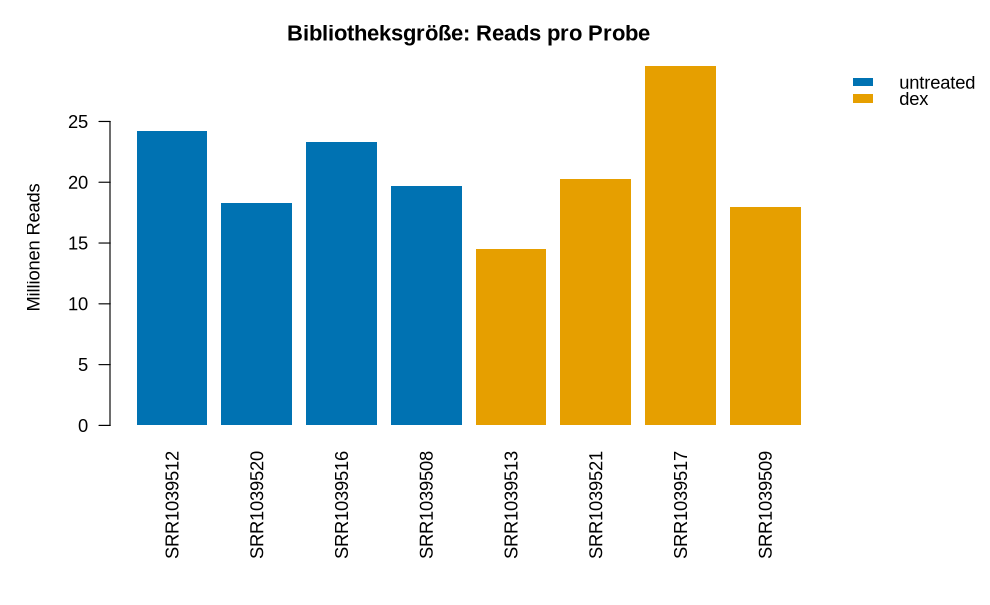

In [3]:
dge <- DGEList(counts = data$counts, samples = data$samples, genes = data$genes)
dim(dge)
plotLibrarySizes(dge, colour_by = "treatment")

<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

Genau wie im Tutorial, mit `data` aus diesem Notebook. Färbe nach `"treatment"`.

</details>

## 2 Gruppen festlegen

Welche Spalte der Probentabelle enthält die Gruppen, die du vergleichen willst? Speichere sie als `dge$samples$group` und zähle die Proben pro Gruppe. Prüfe dann ein bekanntes Glucocorticoid-Gen: **FKBP5**.


untreated       dex 
        4         4 

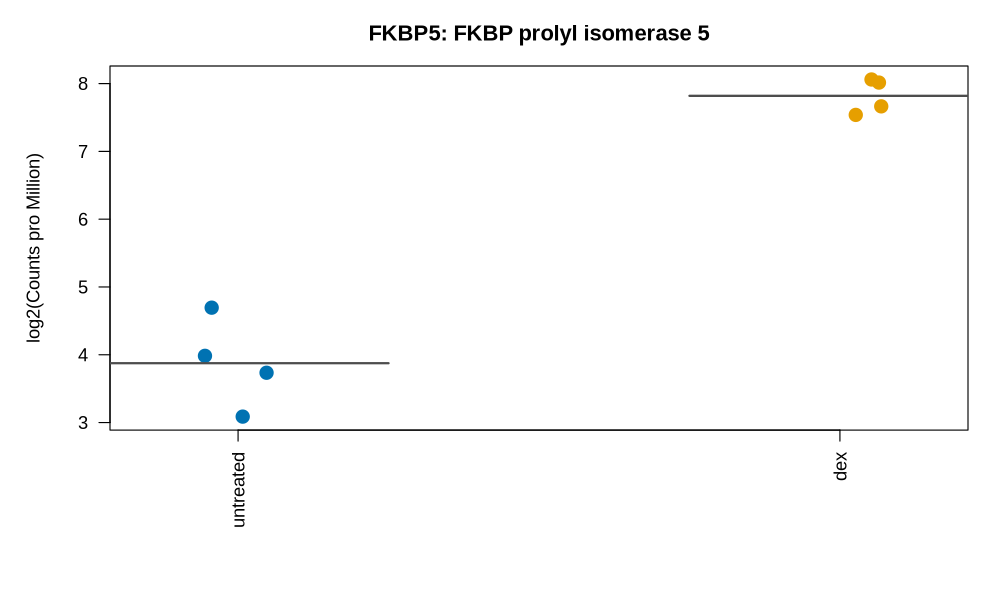

In [4]:
dge$samples$group <- dge$samples$treatment
table(dge$samples$group)
plotGene(dge, "FKBP5", group_by = "treatment")

<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

Die Gruppen sind `untreated` und `dex`, in der Spalte `treatment`: `dge$samples$group <- dge$samples$treatment`. Die Gruppen sind hier schon fertig, du brauchst kein `paste`.

</details>

## 3 Vorbereiten

Filtere, normalisiere und zeichne die Probenkarte. Färbe sie nach Behandlung, dann nach Spender.

[1] 13842     8

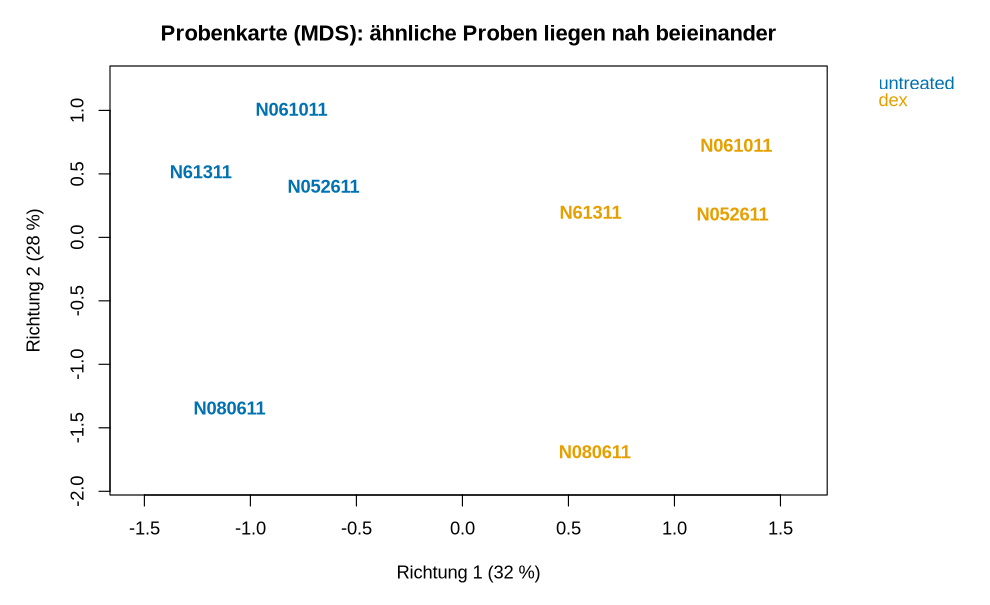

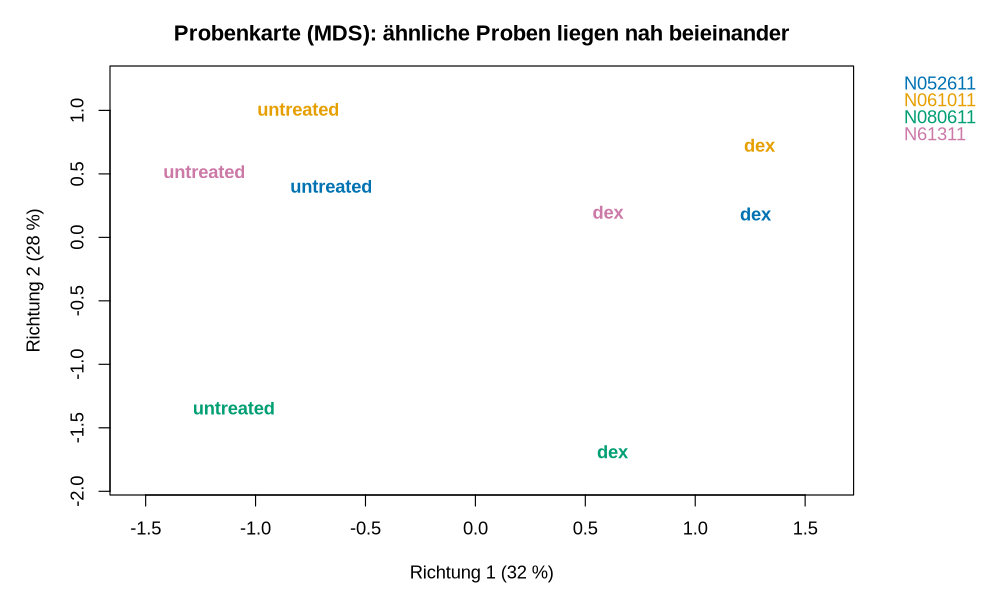

In [5]:
keep <- filterByExpr(dge)
dge <- dge[keep, , keep.lib.sizes = FALSE]
dge <- normLibSizes(dge)
dim(dge)
plotSamples(dge, colour_by = "treatment", label_by = "donor")
plotSamples(dge, colour_by = "donor", label_by = "treatment")

<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

`filterByExpr`, dann `dge[keep, , keep.lib.sizes = FALSE]`, dann `normLibSizes`, wie in Teil 3 des Tutorials. Für die Karte: `plotSamples(dge, colour_by = "donor", label_by = "treatment")`.

</details>

**Frage: Was trennt die Proben entlang Richtung 1? Und entlang Richtung 2?**

✅ **Antwort:** Etwa 13.800 Gene bleiben übrig. Richtung 1 (32 %) trennt **unbehandelt von Dexamethason**. Richtung 2 (28 %) trennt die **Spender**: Die Zellen einer Person ähneln sich, ob behandelt oder nicht. Der Spender hat also fast so viel Einfluss wie das Medikament!

## 4 Design und Kontrast

Hier kommt etwas Neues. Jeder Spender hat **sowohl** unbehandelte als auch behandelte Zellen geliefert: ein **gepaartes** Experiment. Da sich die Spender stark unterscheiden (Schritt 3), vergleichen wir die behandelten Zellen jedes Spenders mit **seinen eigenen** unbehandelten Zellen. Das sagst du limma, indem du den Spender ins Design aufnimmst:

```r
design <- model.matrix(~0 + treatment + donor, data = dge$samples)
```

Sieh dir die Spaltennamen dieses Designs an und schreibe dann den Kontrast `dex_vs_untreated`.

In [6]:
design <- model.matrix(~0 + treatment + donor, data = dge$samples)
colnames(design)
contrasts <- makeContrasts(dex_vs_untreated = treatmentdex - treatmentuntreated, levels = design)
contrasts

[1] "treatmentuntreated" "treatmentdex"       "donorN061011"       "donorN080611"       "donorN61311"

,dex_vs_untreated
treatmentuntreated,-1
treatmentdex,1
donorN061011,0
donorN080611,0
donorN61311,0


<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

Die Spalten heißen `treatmentuntreated`, `treatmentdex` und je eine Spalte pro Spender (außer dem ersten). Die Spender-Spalten fangen nur die Unterschiede zwischen den Spendern auf; der Kontrast benutzt die beiden Behandlungs-Spalten: `makeContrasts(dex_vs_untreated = treatmentdex - treatmentuntreated, levels = design)`.

</details>

## 5 Testen

Führe `voom`, `lmFit`, `contrasts.fit` und `eBayes` aus und zähle die signifikanten Gene.

       dex_vs_untreated
Down               2264
NotSig             9280
Up                 2298

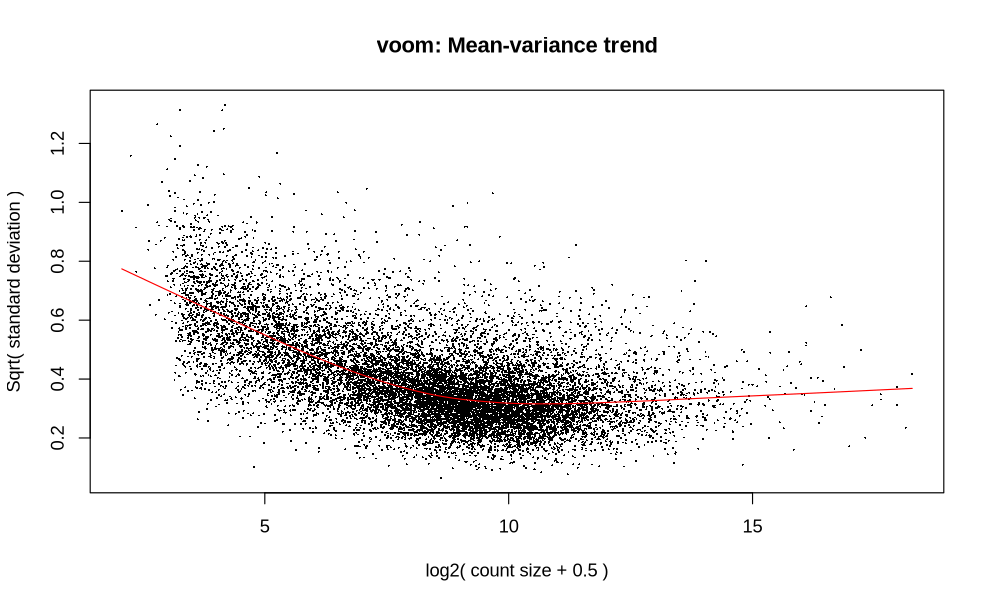

In [7]:
v <- voom(dge, design, plot = TRUE)
fit <- lmFit(v, design)
fit <- contrasts.fit(fit, contrasts)
fit <- eBayes(fit)
summary(decideTests(fit))

<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

Kopiere die beiden Zellen aus Teil 5 des Tutorials; sie funktionieren unverändert.

</details>

**Frage: Wie viele Gene gehen hoch, wie viele runter?**

✅ **Antwort:** Etwa **2.300 hoch** und **2.260 runter** (adjustiertes p < 0,05).

## 6 Deuten

Zeichne den Vulkan-Plot und liste die Top-Gene auf, die hoch und runter gehen. Schlage einige davon nach. Welche haben mit **Entzündung** oder dem **Immunsystem** zu tun?

symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
CACNB2,calcium voltage-gated channel auxiliary sub…,3.27,9.6× höher,3.7,1.1e-06
ALOX15B,arachidonate 15-lipoxygenase type B,8.05,265.7× höher,-1.4,2.6e-06
DUSP1,dual specificity phosphatase 1,2.93,7.6× höher,6.7,2.6e-06
PDPN,podoplanin,1.87,3.7× höher,5.3,2.6e-06
STEAP2,STEAP2 metalloreductase,1.96,3.9× höher,6.9,2.6e-06
SPARCL1,SPARC like 1,4.55,23.4× höher,4.2,2.6e-06
MAOA,monoamine oxidase A,3.32,10.0× höher,6.0,2.6e-06
FGD4,"FYVE, RhoGEF and PH domain containing 4",2.21,4.6× höher,5.5,2.7e-06
NEXN,nexilin F-actin binding protein,2.02,4.1× höher,7.7,2.7e-06


symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
PRSS35,serine protease 35,-2.76,6.8× niedriger,3.3,2.6e-06
WNT2,Wnt family member 2,-3.09,8.5× niedriger,2.8,2.7e-06
DNM1,dynamin 1,-1.78,3.4× niedriger,5.2,3.0e-06
ADAM12,ADAM metallopeptidase domain 12,-1.83,3.6× niedriger,5.7,3.4e-06
CCKAR,cholecystokinin A receptor,-2.20,4.6× niedriger,5.0,4.1e-06
VCAM1,vascular cell adhesion molecule 1,-3.62,12.3× niedriger,3.6,4.2e-06
GXYLT2,glucoside xylosyltransferase 2,-1.59,3.0× niedriger,5.0,4.3e-06
CXCL12,C-X-C motif chemokine ligand 12,-1.92,3.8× niedriger,9.9,6.6e-06
KCTD12,potassium channel tetramerization domain co…,-2.54,5.8× niedriger,6.5,7.1e-06


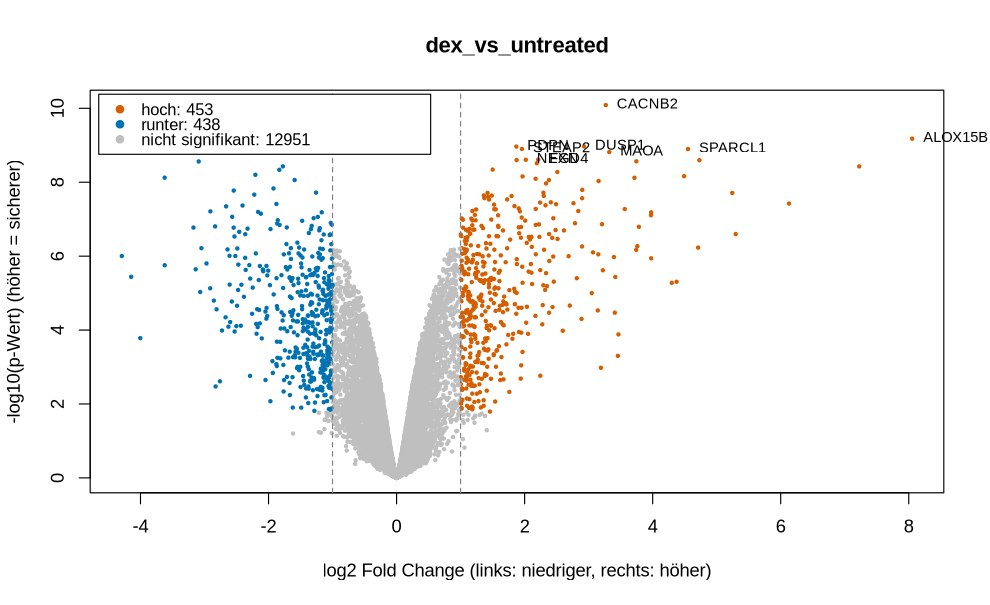

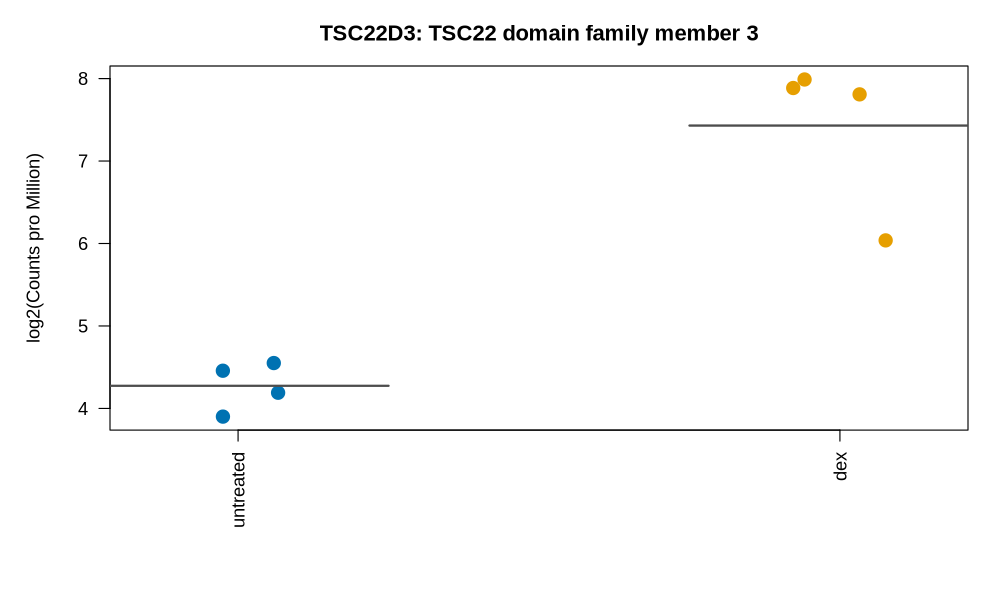

In [8]:
plotVolcano(fit, "dex_vs_untreated")
showTop(fit, "dex_vs_untreated", n = 20, direction = "up")
showTop(fit, "dex_vs_untreated", n = 20, direction = "down")
plotGene(dge, "TSC22D3", group_by = "treatment")

<details><summary>💡 <b>Tipp</b> (zum Öffnen klicken)</summary>

Schlage Gene auf [GeneCards](https://www.genecards.org) nach. Einige bekannte Glucocorticoid-Gene, die du mit `plotGene` prüfen kannst: **DUSP1**, **TSC22D3** (auch GILZ genannt, „glucocorticoid-induced leucine zipper“), **KLF15**, **PER1**, **ZBTB16**. Bei den Genen, die runter gehen, achte auf **VCAM1** und **CXCL12**.

</details>

## Dein Fazit

Beantworte die Forschungsfrage in ein paar Sätzen: Was hast du verglichen, was hast du gefunden, und was bedeutet es? Sei bereit, deinen Vulkan-Plot und deine Antwort der Klasse zu zeigen.

✅ **Antwort:** Wir haben glatte Muskelzellen der Atemwege von 4 Spendern mit und ohne Dexamethason verglichen, mit einem gepaarten Design (Spender im Modell). Etwa 2.300 Gene gingen hoch und 2.260 runter. Hoch: klassische Glucocorticoid-Gene wie *DUSP1*, *TSC22D3* (GILZ), *KLF15*, *PER1*, *FKBP5* und *ZBTB16*. DUSP1 und GILZ sind **Bremsen der Entzündung**: DUSP1 schaltet Entzündungssignale ab, GILZ blockiert den Hauptschalter der Entzündung, NF-κB. Runter: *VCAM1*, an dem Immunzellen im Gewebe festhalten, und das Chemokin *CXCL12*, das Immunzellen anlockt. Dexamethason schaltet also entzündungshemmende Gene an und Gene, die Immunzellen herbeirufen, aus: Das erklärt, wie es die Atemwege beruhigt.

## Bonus: Macht das gepaarte Design einen Unterschied?

Wiederhole die Schritte 4 und 5 **ohne** den Spender: `model.matrix(~0 + treatment, data = dge$samples)`. Vergleiche die Zahl der signifikanten Gene. Warum ist sie anders?

In [9]:
design0 <- model.matrix(~0 + treatment, data = dge$samples)
contrasts0 <- makeContrasts(dex_vs_untreated = treatmentdex - treatmentuntreated, levels = design0)
fit0 <- eBayes(contrasts.fit(lmFit(voom(dge, design0), design0), contrasts0))
summary(decideTests(fit0))

       dex_vs_untreated
Down                861
NotSig            11995
Up                  986

✅ **Antwort:** Ohne den Spender sind nur etwa **1.850** Gene signifikant statt etwa **4.560**. Ohne den Spender im Modell zählen die Unterschiede zwischen den Spendern als „Rauschen“, das Rauschen wirkt also größer und weniger Veränderungen sind überzeugend. Mit dem gepaarten Design vergleicht limma jeden Spender mit sich selbst, und die Spender-Unterschiede fallen weg.

<small>Software: limma (Ritchie et al. 2015) mit voom (Law et al. 2014) und edgeR (Chen et al. 2025) in R. Vollständige Quellen aller Datensätze am Ende von `01_tutorial_milk.ipynb`.</small>